<a href="https://colab.research.google.com/github/evelinbustamante/AAI-520-Multi-Agent_Financial_Analysis_System/blob/main/Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-Agent Financial Analysis System

**AAI-520 Final Team Project: Group 3**

An AI agent that researches a given stock ticker the way a junior analyst
would: it plans its research steps, pulls live data, checks its own output
quality, and keeps notes across runs to improve future analysis.

**Team:** Evelin Bustamante, Paola Marsal, Andrew Fennimore

**Workflows implemented:** Prompt Chaining, Routing, Evaluator-Optimizer

**GitHub:** https://github.com/evelinbustamante/AAI-520-Multi-Agent_Financial_Analysis_System

## Project Overview

**Agent Functions demonstrated:**
- Planning: agent plans research steps for a given ticker
- Tool use: dynamically calls data pull, memory, and analysis tools
- Self-reflection: evaluator checks analysis quality before finalizing
- Learning across runs: agent reads/writes notes per ticker between runs

**Workflow patterns demonstrated:**
- Prompt Chaining: news processing pipeline (Evelin)
- Routing: directs content to the right specialist analyzer (Paola)
- Evaluator-Optimizer: grades and refines analysis output (Andrew)

**Notebook structure:**
1. System Diagram
2. Stock Data Retrieval and Price Chart
3. Memory Across Runs
4. Agent Core (planning and tool use)
5. Prompt Chaining
6. Routing
7. Error Handling
8. Evaluator-Optimizer
9. Full Pipeline Demo (end-to-end run)
10. AI Disclosure

## System Diagram

This diagram shows how the pieces of our agent connect. Our system is
multi-agent: instead of one model doing everything in one prompt, the work
is split across agents that each have their own role, prompt, and job.

- **Orchestrator (Agent Core):** plans the research for a ticker and calls
  the tools it picked, like stock data, financials, and memory.
- **News processor (Prompt Chaining):** reads a news article in small steps
  and labels it as earnings, company news, or market news.
- **Three specialist analysts (Routing):** a fundamentals analyst, a news
  analyst, and a market analyst. The router sends the content to one of
  them based on the label.
- **Evaluator and optimizer (Evaluator-Optimizer):** the evaluator grades
  the analyst's draft and the optimizer rewrites it using the feedback.
- **Memory:** a shared service every agent can read, so each run builds on
  the last one.

All of the agents use the same Llama 3.2 3B model. What makes them separate
agents is that each one gets its own instructions, its own data, and its own
step in the workflow, the same way a team of analysts might share one
office but each own a different part of the report.

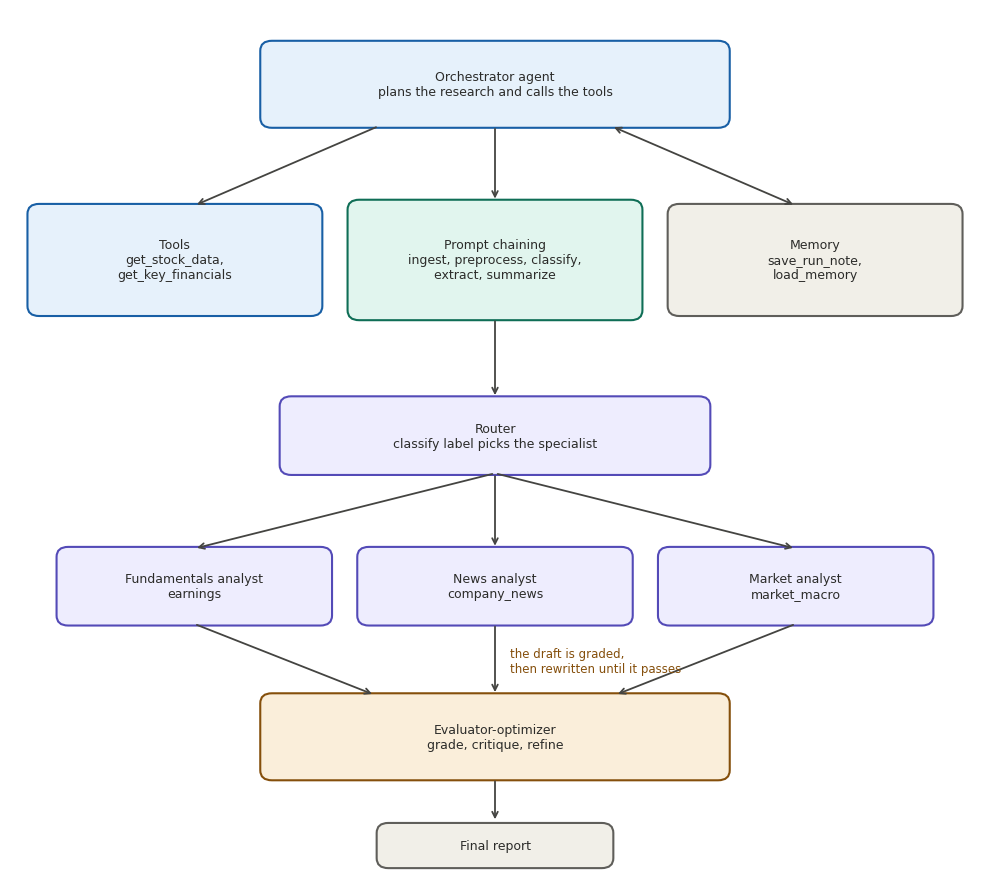

In [ ]:
# Paola
# Workflow diagram: how the pieces of the agent connect
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(10, 9))
ax.set_xlim(0, 10)
ax.set_ylim(-0.4, 10)
ax.axis("off")

COLORS = {
    "agent": ("#E6F1FB", "#185FA5"),
    "chain": ("#E1F5EE", "#0F6E56"),
    "route": ("#EEEDFE", "#534AB7"),
    "eval": ("#FAEEDA", "#854F0B"),
    "store": ("#F1EFE8", "#5F5E5A"),
}


def box(cx, cy, w, h, text, kind):
    fill, edge = COLORS[kind]
    ax.add_patch(FancyBboxPatch((cx - w / 2, cy - h / 2), w, h,
                                boxstyle="round,pad=0.02,rounding_size=0.12",
                                facecolor=fill, edgecolor=edge, linewidth=1.5))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=9, color="#2C2C2A")


def arrow(x1, y1, x2, y2, style="->"):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle=style, color="#444441", linewidth=1.3))


box(5, 9.1, 4.8, 1.0, "Orchestrator agent\nplans the research and calls the tools", "agent")
box(1.7, 7.0, 3.0, 1.3, "Tools\nget_stock_data,\nget_key_financials", "agent")
box(5.0, 7.0, 3.0, 1.4, "Prompt chaining\ningest, preprocess, classify,\nextract, summarize", "chain")
box(8.3, 7.0, 3.0, 1.3, "Memory\nsave_run_note,\nload_memory", "store")
box(5, 4.9, 4.4, 0.9, "Router\nclassify label picks the specialist", "route")
box(1.9, 3.1, 2.8, 0.9, "Fundamentals analyst\nearnings", "route")
box(5.0, 3.1, 2.8, 0.9, "News analyst\ncompany_news", "route")
box(8.1, 3.1, 2.8, 0.9, "Market analyst\nmarket_macro", "route")
box(5, 1.3, 4.8, 1.0, "Evaluator-optimizer\ngrade, critique, refine", "eval")
box(5, 0.0, 2.4, 0.5, "Final report", "store")

arrow(3.8, 8.6, 1.9, 7.65)
arrow(5.0, 8.6, 5.0, 7.7)
arrow(6.2, 8.6, 8.1, 7.65, style="<->")
arrow(5.0, 6.3, 5.0, 5.35)
for x in (1.9, 5.0, 8.1):
    arrow(5.0, 4.45, x, 3.55)
    arrow(x, 2.65, 5.0 + (x - 5.0) * 0.4, 1.8)
ax.text(5.15, 2.2, "the draft is graded,\nthen rewritten until it passes",
        fontsize=8.5, color="#854F0B", va="center")
arrow(5.0, 0.8, 5.0, 0.28)

plt.tight_layout()
plt.show()

## Stock Data Retrieval

We're pulling stock data through the yfinance package since it's free,
doesn't need an API key, and gives us everything we need in one call: price
history, financials, and company info.

We wrapped the raw yfinance output into a function that returns a clean
dictionary instead of printing the raw pandas objects directly. The raw
financials table comes back with almost 40 line items, and most of that
is noise for what the agent actually needs, so we are only pulling out revenue,
net income, operating income, and diluted EPS from the most recent fiscal
year. That keeps the data easy for the agent to reason over downstream,
instead of handing it a wall of accounting terms it has to sort through
itself.

In [ ]:
!pip install yfinance -q

import logging

import yfinance as yf

# Bad tickers are handled in code below, so keep yfinance's own error logs out of the notebook
logging.getLogger("yfinance").setLevel(logging.CRITICAL)


def get_stock_data(ticker: str, period: str = "6mo") -> dict:
    """Pulls price history, financials, and company info for a ticker."""
    stock = yf.Ticker(ticker)
    hist = stock.history(period=period)
    info = stock.info

    return {
        "ticker": ticker,
        "current_price": info.get("currentPrice"),
        "sector": info.get("sector"),
        "market_cap": info.get("marketCap"),
        "52_week_high": info.get("fiftyTwoWeekHigh"),
        "52_week_low": info.get("fiftyTwoWeekLow"),
        "price_history": hist[["Close", "Volume"]].tail(30).to_dict(orient="index"),
    }


def get_key_financials(ticker: str) -> dict:
    """Pulls just the financial metrics that matter, not the full raw statement."""
    stock = yf.Ticker(ticker)
    fin = stock.financials
    if fin is None or fin.empty:
        return {"error": f"No financial statements found for {ticker}"}
    latest_year = fin.columns[0]
    return {
        "fiscal_year": str(latest_year.date()),
        "total_revenue": float(fin.loc["Total Revenue", latest_year]) if "Total Revenue" in fin.index else None,
        "net_income": float(fin.loc["Net Income", latest_year]) if "Net Income" in fin.index else None,
        "operating_income": float(fin.loc["Operating Income", latest_year]) if "Operating Income" in fin.index else None,
        "diluted_eps": float(fin.loc["Diluted EPS", latest_year]) if "Diluted EPS" in fin.index else None,
    }


# Test it
data = get_stock_data("AAPL")
price = data["current_price"]
market_cap = data["market_cap"]

print(f"Ticker: {data['ticker']}")
print(f"Current Price: ${price:.2f}" if price is not None else "Current Price: n/a")
print(f"Sector: {data['sector']}")
print(f"Market Cap: ${market_cap:,}" if market_cap is not None else "Market Cap: n/a")
print(f"52-Week Range: ${data['52_week_low']} - ${data['52_week_high']}")

Ticker: AAPL
Current Price: $343.46
Sector: Technology
Market Cap: $5,012,516,765,696
52-Week Range: $243.42 - $348.15


## Price Chart

This chart plots AAPL's closing price over the last 30 trading days, using the same price_history our data function hands to the agent.


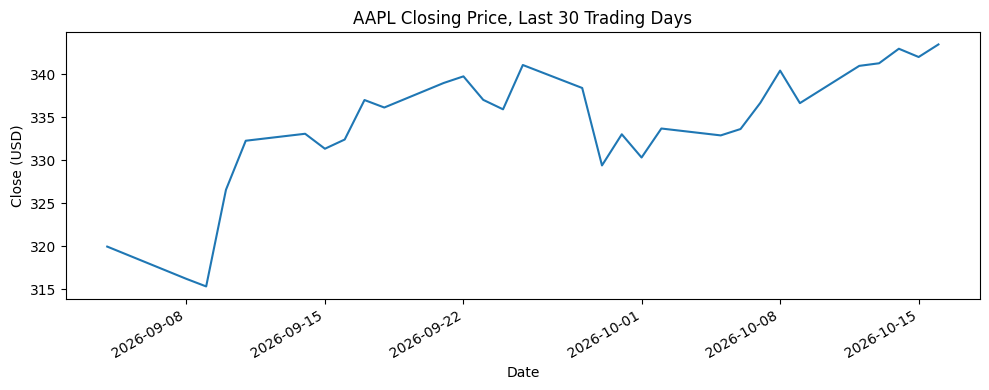

In [ ]:
# Paola
import matplotlib.pyplot as plt

data = get_stock_data("AAPL")
dates = list(data["price_history"].keys())
closes = [row["Close"] for row in data["price_history"].values()]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dates, closes)
ax.set_title("AAPL Closing Price, Last 30 Trading Days")
ax.set_xlabel("Date")
ax.set_ylabel("Close (USD)")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Memory Across Runs

This part covers the "learns across runs" requirement for our agent. After
each analysis, save_memory() writes a short note to a JSON file for that
ticker, just a date and a few key findings. Before the agent starts a new
run, load_memory() reads back whatever notes already exist for that ticker,
so it's not starting from zero every time. save_run_note() is the shortcut
the agent uses at the end of a run, and memory_context() turns the last two
notes into plain text the specialists can read in their prompts.

We kept this simple on purpose. A vector store would let the agent search
past notes by meaning instead of just pulling everything back, but given
where we are with Python right now as a team, a plain JSON file is easier
to explain, easier to debug, and does the job the rubric is actually
asking for.

One limitation to flag: the notes are saved in the Colab session's files,
so they last across runs within a session but are wiped when the runtime
resets. In a real deployment we would save them to Google Drive or a
database so memory carries over between sessions too.

In [ ]:
import json
import os
from datetime import datetime

MEMORY_DIR = "agent_memory"
os.makedirs(MEMORY_DIR, exist_ok=True)

def save_memory(ticker: str, note: str, key_findings: dict = None):
    """Appends a note after an analysis run."""
    path = f"{MEMORY_DIR}/{ticker}.json"
    entries = []
    if os.path.exists(path):
        with open(path, "r") as f:
            entries = json.load(f)

    entries.append({
        "date": datetime.now().strftime("%Y-%m-%d"),
        "note": note,
        "key_findings": key_findings or {}
    })

    with open(path, "w") as f:
        json.dump(entries, f, indent=2)

def load_memory(ticker: str) -> list:
    """Reads past notes for a ticker, used before generating new analysis."""
    path = f"{MEMORY_DIR}/{ticker}.json"
    if not os.path.exists(path):
        return []
    with open(path, "r") as f:
        return json.load(f)

# Read back any saved notes for this ticker
past_notes = load_memory("AAPL")
print(f"Found {len(past_notes)} note(s) for AAPL")
for note in past_notes:
    print(f"  {note['date']}: {note['note']}")

Found 0 note(s) for AAPL


In [ ]:
# Paola
# Memory write-back: the agent saves what it found, then reads it back as context

def save_run_note(ticker: str, price: float, summary: str = "",
                  sentiment: str = "", category: str = "") -> None:
    """Saves one note after an analysis run, in the format load_memory reads."""
    parts = [f"{ticker} run"]
    if category:
        parts.append(f"category {category}")
    if sentiment:
        parts.append(f"sentiment {sentiment}")
    save_memory(ticker, ", ".join(parts), {
        "price": price,
        "category": category,
        "sentiment": sentiment,
        "summary": summary,
    })


def memory_context(ticker: str, last_n: int = 2) -> str:
    """Turns the most recent notes into plain text a prompt can include."""
    notes = load_memory(ticker)[-last_n:]
    if not notes:
        return ""
    lines = []
    for note in notes:
        findings = note.get("key_findings", {})
        price = findings.get("price")
        price_text = f"${price:.2f}" if isinstance(price, (int, float)) else "n/a"
        lines.append(f"- {note['date']}: price {price_text}, "
                     f"sentiment {findings.get('sentiment') or 'n/a'}. "
                     f"{findings.get('summary', '')}")
    return "Notes from earlier runs:\n" + "\n".join(lines)


# Test with a throwaway ticker so the AAPL memory stays clean
save_run_note("TEST", 100.0, summary="Sample finding.",
              sentiment="neutral", category="company_news")
print(memory_context("TEST"))
os.remove("agent_memory/TEST.json")

Notes from earlier runs:
- 2026-10-16: price $100.00, sentiment neutral. Sample finding.


## Agent Core

This section is the "brain" of our project. You give the agent a stock
ticker, like AAPL for Apple, and before doing anything it decides what
research to do. Then it carries out that plan one step at a time, the same
way a junior analyst might write a to-do list before starting work.

How the agent makes its plan: we give Llama 3.2 (a free AI language model
from Meta) a short list of the tools the agent can use, with a one-line
description of each. Llama picks which tools to use, puts them in order,
and gives a short reason for each one. If Llama ever answers in a way the
code can't read, the agent stops and prints Llama's answer so we can see
what went wrong.

What the tools are: the agent doesn't collect any data on its own. It uses
two functions from the sections above, and it depends on what each one
gives back:

- get_stock_data(ticker) looks up the stock on Yahoo Finance. It gives back
  the current price (current_price), the company's industry (sector), the
  total value of all its shares (market_cap), the highest and lowest prices
  of the past year (52_week_high and 52_week_low), and the last 30 days of
  closing prices and trading volume (price_history).
- load_memory(ticker) reads the notes saved from earlier runs on the same
  stock. Each note has the date (date), a short sentence about what was
  found (note), and the stock price on that day (key_findings). If the
  agent hasn't looked at this stock before, there are no notes yet.

How the agent uses its tools: every tool is listed in one place, called
TOOLS, and the agent asks for a tool by its name through call_tool(). This
makes it easy to add more tools later, since a new tool only needs to be
added to that list. If a tool runs into a problem, like a misspelled ticker
or a dropped internet connection, the agent gets a short error message back
instead of the whole program crashing.

How the agent learns across runs: if there are notes from an earlier run,
the agent shows the most recent one and compares the price saved back then
to today's price, so you can see how much the stock has moved since the
last time it looked.

In [ ]:
#Andrew (updated Oct 11, 2026)
#Load Llama for the planner, on a GPU or the CPU

%pip install transformers accelerate -q

import os
import torch
from huggingface_hub import login
from transformers import pipeline
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

# Llama 3.2 is the AI model the agent uses to plan its research steps.
try:
    from google.colab import userdata  # only exists in Colab
    hf_token = userdata.get("HF_TOKEN")
except Exception:  # not in Colab, or the HF_TOKEN secret isn't set
    hf_token = os.environ.get("HF_TOKEN")
if hf_token:
    login(token=hf_token)

# Use the GPU if this computer has one, otherwise the CPU, so the notebook
# runs on any machine. bfloat16 is the CPU-friendly version of float16, and
# both keep the model at about 6.4 GB of memory.
if torch.cuda.is_available():
    dtype, device_map = torch.float16, "auto"
else:
    dtype, device_map = torch.bfloat16, "cpu"
    print("No GPU found, so Llama will run on the CPU. That works but is "
          "much slower. (In Colab: Runtime > Change runtime type > T4 GPU)\n")

MODEL = "meta-llama/Llama-3.2-3B-Instruct"

generator = pipeline(
    "text-generation",
    model=MODEL,
    dtype=dtype,
    device_map=device_map,)


def call_llm(prompt: str, system: str = "", max_tokens: int = 600) -> str:
    """Sends one prompt to Llama and returns its reply as plain text."""
    messages = []
    if system:
        messages.append({"role": "system", "content": system})
    messages.append({"role": "user", "content": prompt})
    output = generator(messages, max_new_tokens=max_tokens, do_sample=False)
    return output[0]["generated_text"][-1]["content"].strip()

config.json:   0%|          | 0.00/878 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

In [ ]:
#Andrew
#Tool registry + tool-calling stub

# Every tool the agent is allowed to use, looked up by name. New tools can
# be added later as new entries here.
TOOLS = {
    "load_memory": {
        "function": load_memory,
        "description": "Reads notes saved from past runs on this ticker.",},
    "get_stock_data": {
        "function": get_stock_data,
        "description": "Pulls current price, sector, market cap, 52-week "
                       "range, and recent daily prices.",},}


def call_tool(tool_name: str, **kwargs):
    """Runs a tool by name. Returns an error dict instead of crashing the agent."""
    if tool_name not in TOOLS:
        return {"error": f"Unknown tool: {tool_name}"}
    try:
        return TOOLS[tool_name]["function"](**kwargs)
    except Exception as error:  # bad ticker, network hiccup, etc.
        return {"error": str(error)}

In [ ]:
# Paola
TOOLS["get_key_financials"] = {
    "function": get_key_financials,
    "description": "Pulls revenue, net income, operating income, and "
                   "diluted EPS from the latest fiscal year.",
}

In [ ]:
#Andrew
#Planning step

import json
import re


def plan_research(ticker: str) -> list:
    """Asks Llama which tools to call, and in what order, before pulling any data."""
    tool_list = "\n".join(f"- {name}: {tool['description']}"
                          for name, tool in TOOLS.items())
    prompt = (
        f"You are a junior analyst planning research on the stock {ticker}.\n"
        f"Available tools:\n{tool_list}\n\n"
        "List the tools to call, in order, to research this stock well. "
        "Reply with ONLY a JSON list with one entry per tool, like this:\n"
        '[{"tool": "tool_name", "why": "short reason"}, '
        '{"tool": "tool_name", "why": "short reason"}]')
    reply = call_llm(prompt, max_tokens=200)
    match = re.search(r"\[.*\]", reply, re.DOTALL)  # grab the JSON list only
    try:
        steps = json.loads(match.group(0))
        # smaller models sometimes reply with just names, like ["load_memory"]
        steps = [{"tool": s} if isinstance(s, str) else s for s in steps]
        plan = []
        for step in steps:
            tool = step.get("tool")
            if tool in TOOLS and tool not in [s["tool"] for s in plan]:
                plan.append(step)  # skip unknown tools and repeats
    except (AttributeError, TypeError, json.JSONDecodeError):
        plan = []

    if not plan:
        raise ValueError(f"Could not read a plan from Llama's reply:\n{reply}")
    return plan

In [ ]:
#Andrew (updated Oct 12, 2026)
#Agent loop: plan, then call each tool
# Paola (Oct 16): added save_note flag so the full pipeline can save one richer note instead

def run_agent(ticker: str, verbose: bool = True,
              save_note: bool = True) -> dict:
    """Plans the research for a ticker, then runs each planned tool in order."""

    def show(message: str) -> None:
        if verbose:
            print(message)

    # 1. Plan
    plan = plan_research(ticker)
    show(f"Plan for {ticker}:")
    for number, step in enumerate(plan, start=1):
        show(f"  {number}. {step['tool']}: {step.get('why', '')}")

    # 2. Act: call each tool by name and keep its output
    results = {}
    for number, step in enumerate(plan, start=1):
        tool_name = step["tool"]
        show(f"\nStep {number}: {tool_name}")
        output = call_tool(tool_name, ticker=ticker)
        results[tool_name] = output

        if isinstance(output, dict) and "error" in output:
            show(f"  error: {output['error']}")
        elif tool_name == "load_memory":
            show(f"  found {len(output)} past note(s)")
        elif tool_name == "get_stock_data":
            price = output.get("current_price")
            if price is None:  # yfinance often returns None for a bad ticker
                show("  no price returned, bad ticker?")
            else:
                show(f"  price ${price:.2f}, sector {output.get('sector')}")

    # 3. Learning across runs: compare today's price to the last saved one
    past_notes = results.get("load_memory")
    price_now = (results.get("get_stock_data") or {}).get("current_price")
    if isinstance(past_notes, list) and past_notes:
        last = past_notes[-1]
        show(f"\nLast run ({last['date']}): {last['note']}")
        price_then = last.get("key_findings", {}).get("price")
        if price_then and price_now:
            change = (price_now - price_then) / price_then * 100
            show(f"  price then ${price_then:.2f} -> now ${price_now:.2f} "
                 f"({change:+.1f}%)")

    # 4. Save a note so the next run has a price to compare against.
    # The full pipeline turns this off and saves its own note at the end.
    if price_now and save_note:  # skip for a bad ticker or a plan without get_stock_data
        save_run_note(ticker, price_now)
        show(f"\nSaved a note for {ticker}")

    return {"ticker": ticker, "plan": plan, "results": results}

In [ ]:
#Andrew
#Test

# Llama plans the research steps, then the agent runs them in order.
agent_result = run_agent("AAPL")

[transformers] Both `max_new_tokens` (=200) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Plan for AAPL:
  1. load_memory: to retrieve historical data and notes
  2. get_stock_data: to get current price, sector, market cap, 52-week range, and recent daily prices
  3. get_key_financials: to get revenue, net income, operating income, and diluted EPS

Step 1: load_memory
  found 1 past note(s)

Step 2: get_stock_data
  price $343.46, sector Technology

Step 3: get_key_financials

Last run (2026-10-16): AAPL run
  price then $343.46 -> now $343.46 (+0.0%)

Saved a note for AAPL


## Prompt Chaining
Financial news articles can include load of information, crossing different sectors and including multi-dimesnioned explinations of pricing. Our prompt chain turns all that noise into data that the rest of our agent can use.

Our prompt chain breaks down information into 5 steps, allowing for predictability in the next step, and the ability to trace where possible errors occured.  The structured, trustworthy steps are Ingest > Preprocess > Classify > Extract > Summarize.  Instead of one large prompt, the five steps allow for the pipeline to focus on one task, with the security of a saftey net.

 - **Ingest :** Pulls the news article from the source, either yfinance or provided personally.  If the fetch fails, the chain stops, instead of crashing or wasting an LLM call.
 - **Preprocess :** The clean up phase, stripping HTML, cleaning whitespaces, triming length.  If the article is not sufficent or long enough the chain stops instead of hallucinating answers and wasting a LLM call.
 - **Classify :** Categorizing the articles, which will be handed off to routing later.  The categories will make sure an article gets sent to the right specialist, if the article does not match it will just be labeled as company_news.
 - **Extract :** The key part of turning financial noise into data, extracting important features, company names, numbers, and events. An important rule to point out is how every number must be connected to a who or what, to limit confusion, so a price never shows up alone.
 - **Summarize :** Finally, taking the extracted data and creating a 2-3 sentance summary, all supported by the data that was extracted. This keeps the prompt chain clean and easy to follow, especially when prices come up.

 These small and focused steps allow us to have a prompt chain that is trustworthy and reliable. Each step is clean and predictable, with fail safes and check points every step of the way. At the end of the chain you can see our Apple test, pulled directly from the Yahoo Finance manually.  The chain was able to pull important prices and attribute them to their respected companies (Morgan Stanley and Bank of America), highlight the struggling job cuts and produce an analytical summary. This prompt chain is the core of our agentic workflow.


In [ ]:
#Evelin

import json
import json
import re

import yfinance as yf

CATEGORIES = ["earnings", "company_news", "market_macro"]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

In [ ]:
#Evelin
#Step 1 - Ingest

def ingest(ticker: str, article: str = None) -> dict:
    """Gets raw article text. Uses the text passed in, else tries yfinance news."""
    if article:
        return {"ticker": ticker, "raw_text": article, "source": "provided"}

    try:
        items = yf.Ticker(ticker).news or []
        if items:
            content = items[0].get("content", {})
            text = f"{content.get('title', '')}. {content.get('summary', '')}"
            return {"ticker": ticker, "raw_text": text, "source": "yfinance"}
    except Exception as error:  # network hiccup, changed API shape, etc.
        print(f"  (yfinance news failed: {error})")

    return {"ticker": ticker, "raw_text": "", "source": "none"}

In [ ]:
#Evelin
#Step 2 - Preprocess

def preprocess(raw_text: str, max_chars: int = 4000) -> str:
    """Strips HTML tags and extra whitespace, trims length. Returns '' if too short."""
    text = re.sub(r"<[^>]+>", " ", raw_text)  # drop HTML tags
    text = re.sub(r"\s+", " ", text).strip()  # collapse whitespace
    if len(text) < 50:  # not enough to analyze
        return ""
    return text[:max_chars]

In [ ]:
#Evelin
#Step 3 - Classify

def classify(text: str) -> str:
    """Labels the article so Routing can send it to the right specialist."""
    prompt = (
        "Classify this financial news article into exactly one category:\n"
        "- earnings: quarterly/annual results, EPS, revenue, guidance\n"
        "- company_news: products, leadership, deals, legal, operations\n"
        "- market_macro: broad market, rates, economy, sector-wide trends\n\n"
        f"Article:\n{text}\n\n"
        "Reply with only the category name."
    )
    reply = call_llm(prompt, max_tokens=20).lower()
    for label in CATEGORIES:  # smaller models sometimes add extra words
        if label in reply:
            return label
    return "company_news"

In [ ]:
#Evelin
#Step 4 - Extract

def extract(text: str, category: str) -> dict:
    """Pulls structured facts out of the article as a dictionary."""
    prompt = (
    f"This is a {category} article. Extract the key facts.\n"
    "Reply with ONLY valid JSON in exactly this format:\n"
    '{"companies": ["Acme Corp"], '
    '"key_numbers": ["Goldman Sachs price target $100", "new phone price $999"], '
    '"key_events": ["job cuts announced"], "sentiment": "neutral"}\n'
    "Rules for key_numbers: every entry must start with WHO or WHAT the "
    "number belongs to (for example the firm name and 'price target'). "
    "Never write a bare number like '$100'.\n"
    "sentiment must be positive, negative, or neutral.\n\n"
    f"Article:\n{text}"
)
    reply = call_llm(prompt, max_tokens=700)
    match = re.search(r"\{.*\}", reply, re.DOTALL)  # grab the JSON block only
    try:
        return json.loads(match.group(0))
    except (AttributeError, json.JSONDecodeError):
        print("  (extract: could not parse JSON, raw reply below)")
        print(reply)
        return {"companies": [], "key_numbers": [], "key_events": [],
                "sentiment": "neutral", "parse_error": True}

In [ ]:
#Evelin
#Step 5 - Summarize

def summarize(facts: dict, ticker: str) -> str:
    """Turns the extracted facts into a short, plain-English analyst take."""
    prompt = (
    f"You are a junior equity analyst covering {ticker}. Using only these "
    f"extracted facts, write a 2-3 sentence summary for an investor. "
    f"Be clear and plain, no jargon. "
    f"Numbers labeled as price targets are analyst forecasts, not the "
    f"current stock price, so never describe the stock as trading at or "
    f"between them.\n\nFacts:\n{json.dumps(facts, indent=2)}"
)
    return call_llm(prompt, max_tokens=250)

In [ ]:
#Evelin
#The full chain

def run_news_chain(ticker: str, article: str = None, verbose: bool = True) -> dict:
    """Runs Ingest -> Preprocess -> Classify -> Extract -> Summarize."""

    def show(step: str, output) -> None:
        if verbose:
            print(f"\n--- {step} ---\n{output}")

    raw = ingest(ticker, article)
    show("1. INGEST", f"source: {raw['source']}, {len(raw['raw_text'])} chars")

    text = preprocess(raw["raw_text"])
    if not text:  # empty-news handling
        show("2. PREPROCESS", "No usable article text, stopping chain.")
        return {"ticker": ticker, "status": "no_news", "category": None,
                "facts": {}, "summary": "No usable news found."}
    show("2. PREPROCESS", text[:200] + ("..." if len(text) > 200 else ""))

    category = classify(text)
    show("3. CLASSIFY", category)

    facts = extract(text, category)
    show("4. EXTRACT", json.dumps(facts, indent=2))

    summary = summarize(facts if not facts.get("parse_error") else {"article": text}, ticker)
    show("5. SUMMARIZE", summary)

    return {"ticker": ticker, "status": "ok", "category": category,
            "facts": facts, "summary": summary}


In [ ]:
#Evelin
article_text = """
Leadership And Restructuring from Apple: Reports say John Ternus, Apple CEO, is pushing a major overhaul, including targeted job cuts and cancellations of lower-priority projects. The goal is to concentrate resources on products with stronger growth and margin potential.
Analyst Views: Morgan Stanley cut its target to $355 from $360 and kept an Overweight rating. Bank of America kept Buy and $370, but warned that AI agents could change how users discover and buy products.
Product Pipeline: Apple’s fall lineup includes a new smart-home hub on October 13 and the $1,999 iPhone Duo on October 23. Analysts see these launches as key tests of Apple’s AI strategy and consumer demand.
Risks And Offsets: The main pressure points are higher memory costs, softer pricing power, and possible disruption from AI competition. Offset factors include Apple’s broad installed base, Services strength, and continued analyst support.
"""

#Pulled directly from Yahoo Finance AAPL news on October 1, 2026

In [ ]:
#Evelin
#Test

result = run_news_chain("AAPL", article=article_text)

[transformers] Both `max_new_tokens` (=20) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



--- 1. INGEST ---
source: provided, 925 chars

--- 2. PREPROCESS ---
Leadership And Restructuring from Apple: Reports say John Ternus, Apple CEO, is pushing a major overhaul, including targeted job cuts and cancellations of lower-priority projects. The goal is to conce...


[transformers] Both `max_new_tokens` (=700) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



--- 3. CLASSIFY ---
company_news


[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



--- 4. EXTRACT ---
{
  "companies": [
    "Apple"
  ],
  "key_numbers": [
    "Morgan Stanley target $355",
    "Bank of America target $370"
  ],
  "key_events": [
    "job cuts announced"
  ],
  "sentiment": "neutral"
}

--- 5. SUMMARIZE ---
Here's a summary for an investor:

Apple is currently facing some challenges, including job cuts, but analysts are still optimistic about the company's future. They expect Apple's stock price to reach $355 per share, according to Morgan Stanley, or $370 per share, according to Bank of America. Overall, the outlook for Apple remains neutral, indicating a balanced view of the company's prospects.


## Routing

Routing sends each piece of content to the right specialist. The category label from the prompt chain's classify step (earnings, company_news, or market_macro) picks the specialist: a fundamentals analyst, a news analyst, or a market analyst. Each specialist is its own call to the model with its own role and its own data, and an unknown label falls back to the news analyst.


In [ ]:
# Paola
# Routing: sends content to the right specialist based on the category label

def _memory_text(ticker: str) -> str:
    """Earlier notes as prompt text, or an empty string if there are none."""
    text = memory_context(ticker)
    if not text:
        return ""
    return text + "\nThese notes are context only. Do not repeat them as new facts.\n\n"


def fundamentals_analyst(ticker: str, content: dict) -> str:
    """Handles earnings content using the key financials tool."""
    financials = call_tool("get_key_financials", ticker=ticker)
    if "error" in financials:
        return f"Financials unavailable for {ticker}: {financials['error']}"
    prompt = (
        f"{_memory_text(ticker)}"
        f"Financials for {ticker}:\n{json.dumps(financials, indent=2)}\n\n"
        f"Facts from the news:\n{json.dumps(content, indent=2)}\n\n"
        "Write 2-3 plain sentences on what this means for earnings. "
        "Only use numbers shown above."
    )
    return call_llm(prompt, system="You are an earnings analyst.", max_tokens=250)


def news_analyst(ticker: str, content: dict) -> str:
    """Handles company news using the facts the prompt chain extracted."""
    if not content or content.get("parse_error"):
        return f"No usable news facts for {ticker}."
    prompt = (
        f"{_memory_text(ticker)}"
        f"Facts from a news article about {ticker}:\n"
        f"{json.dumps(content, indent=2)}\n\n"
        "Write 2-3 plain sentences on what this means for the company. "
        "Do not call analyst price targets the current price."
    )
    return call_llm(prompt, system="You are a company news analyst.", max_tokens=250)


def market_analyst(ticker: str, content: dict) -> str:
    """Handles market-wide content using the recent price history."""
    data = call_tool("get_stock_data", ticker=ticker)
    if "error" in data:
        return f"Price data unavailable for {ticker}: {data['error']}"
    closes = [row["Close"] for row in data["price_history"].values()]
    if len(closes) < 2:
        return f"Not enough price history for {ticker}."
    change = (closes[-1] - closes[0]) / closes[0] * 100
    prompt = (
        f"{_memory_text(ticker)}"
        f"{ticker} moved {change:+.1f}% over the last 30 trading days.\n"
        f"Market-level facts:\n{json.dumps(content, indent=2)}\n\n"
        "Write 2-3 plain sentences connecting the two."
    )
    return call_llm(prompt, system="You are a market analyst.", max_tokens=250)


SPECIALISTS = {
    "earnings": fundamentals_analyst,
    "company_news": news_analyst,
    "market_macro": market_analyst,
}


def route(category: str, ticker: str, content: dict) -> dict:
    """Picks the specialist for a category and runs it."""
    specialist = SPECIALISTS.get(category, news_analyst)  # safe default
    return {"specialist": specialist.__name__,
            "analysis": specialist(ticker, content)}

In [ ]:
# Paola
# Checks the router picks the right specialist, including the fallback
for category in ["earnings", "company_news", "market_macro", "unknown_label"]:
    print(category, "->", SPECIALISTS.get(category, news_analyst).__name__)

earnings -> fundamentals_analyst
company_news -> news_analyst
market_macro -> market_analyst
unknown_label -> news_analyst


In [ ]:
# Paola
# Live routing test: send the prompt chain's output to the matching specialist.
# Uses `result` from the Prompt Chaining test above, so run that section first.

routed = route(result["category"], "AAPL", result["facts"])

print(f"Category from the chain: {result['category']}")
print(f"Specialist picked: {routed['specialist']}")
print(f"\nAnalysis:\n{routed['analysis']}")

[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Category from the chain: company_news
Specialist picked: news_analyst

Analysis:
The recent announcement of job cuts by Apple has led to a neutral sentiment, indicating that investors are neither strongly bullish nor bearish on the company's prospects. The price target set by Morgan Stanley at $355 and Bank of America at $370 suggests that some analysts expect Apple's stock to continue its upward trend, but the neutral sentiment suggests that this growth may be slowing down. Overall, the news has likely had a mixed impact on investor sentiment.


## Error Handling

These checks send the specialists bad input: a ticker that doesn't exist and an empty news result. Each one returns a plain message instead of crashing the agent, so the rest of the run can keep going.

In [ ]:
# Paola
# Guard checks: bad input should return a message, not crash (no model needed)
print(fundamentals_analyst("ZZZZNOTREAL", {"sentiment": "neutral"}))
print(market_analyst("ZZZZNOTREAL", {"sentiment": "neutral"}))
print(news_analyst("AAPL", {}))

Financials unavailable for ZZZZNOTREAL: No financial statements found for ZZZZNOTREAL
Not enough price history for ZZZZNOTREAL.
No usable news facts for AAPL.


## Evaluator-Optimizer

This section is where the agent checks its own work before handing it
over. It covers the Evaluator-Optimizer workflow and the "self-reflects"
agent function.

How it works: the agent starts with a draft analysis, an evaluator grades
it, and if the grade is too low an optimizer rewrites the draft using the
evaluator's feedback. The new draft is then graded again. The loop stops
as soon as a draft passes, or after three rounds so it can't run forever.

The evaluator has two parts:

- A number check written in plain Python (no AI). It finds every dollar
  amount in the draft and makes sure it actually appears in the source
  data. It also catches the draft calling some other number the "current
  price". We added this because a small model like Llama 3.2 3B tends to
  go easy on writing like its own, and a wrong number is the worst mistake
  a stock note can make.
- A grade from Llama. Llama scores the draft from 1 to 5 on four rules:
  every number and comparison (above, below, within) matches the source
  data, analyst price targets are never called the current price, it is
  plain and short (2-4 sentences), and it says what the news means for the
  stock. It replies with a score and a line or two of feedback.

A draft passes only if Llama gives it at least 4 out of 5 and the number
check finds no problems. When a draft fails, the number check's problems
are listed first in the feedback, since we know those are real mistakes.

The test below uses a real mistake from an earlier run of our prompt
chain: the summary said Apple's "current stock price is between \$355 and
\$370", but those were analyst price targets, not the price. The output
shows each round's score and feedback, so you can see the draft improve.

In [ ]:
#Andrew (added Oct 11, 2026)
#Number check: plain Python, no model needed

import json
import re

# A dollar amount like "$355", "$1,999", or "$391 billion"
DOLLAR = re.compile(
    r"\$\s?(\d[\d,]*(?:\.\d+)?)\s*(trillion|billion|million|bn|[tbm])?\b",
    re.IGNORECASE)
SCALE = {"trillion": 1e12, "t": 1e12, "billion": 1e9, "bn": 1e9, "b": 1e9,
         "million": 1e6, "m": 1e6}

# The draft calling a number the current price, like "trading at $355"
CURRENT_PRICE = re.compile(
    r"(?:current(?:ly)?\s+(?:stock\s+|share\s+)?(?:price|trading)|trading at)"
    r"[^$]{0,40}?\$\s?(\d[\d,]*(?:\.\d+)?)",
    re.IGNORECASE)


def dollar_amounts(text: str) -> list:
    """Every $ amount in the text as a number, '$391 billion' -> 391e9."""
    return [float(number.replace(",", "")) * SCALE.get(scale.lower(), 1)
            for number, scale in DOLLAR.findall(text)]


def check_numbers(draft: str, facts: dict) -> list:
    """Lists number problems in the draft. An empty list means none found."""
    source = json.dumps(facts)
    known = [float(n.replace(",", ""))
             for n in re.findall(r"\d[\d,]*(?:\.\d+)?", source)]
    known += dollar_amounts(source)  # "$391 billion" written inside a fact

    problems = []
    for amount in dollar_amounts(draft):
        # within 1% so rounding like "$391 billion" still counts as a match
        if not any(abs(amount - k) <= 0.01 * k for k in known):
            problems.append(f"${amount:,.2f} does not appear in the source "
                            "data.")

    price = facts.get("current_price")
    if price:
        for match in CURRENT_PRICE.finditer(draft):
            amount = float(match.group(1).replace(",", ""))
            if abs(amount - price) > 0.01 * price:
                problems.append(f"Calls ${amount:,.2f} the current price, but "
                                f"the current price is ${price:,.2f}. Numbers "
                                "labeled as targets are analyst forecasts.")
    return problems


# Quick test, no model needed
sample_facts = {"current_price": 333.63,
                "key_numbers": ["Morgan Stanley price target $355"]}
print(check_numbers("Apple is currently trading at $355.", sample_facts))
print(check_numbers("Morgan Stanley's $355 target is above the current price "
                    "of $333.63.", sample_facts))
print(check_numbers("Apple could reach $500 this year.", sample_facts))

['Calls $355.00 the current price, but the current price is $333.63. Numbers labeled as targets are analyst forecasts.']
[]
['$500.00 does not appear in the source data.']


In [ ]:
#Andrew (added Oct 11, 2026)
#Evaluator: grade the draft

def evaluate_analysis(draft: str, ticker: str, facts: dict) -> dict:
    """Grades a draft 1-5 with Llama and runs the number check on it."""
    prompt = (
        f"Source data for {ticker}:\n{json.dumps(facts, indent=2)}\n\n"
        f"Draft analyst note:\n{draft}\n\n"
        "Grade the draft from 1 (poor) to 5 (excellent) using these rules:\n"
        "1. Every number in the draft matches the source data, and every "
        "comparison (above, below, within) is correct.\n"
        "2. Analyst price targets are never described as the current price.\n"
        "3. It is plain and short (2-4 sentences), with no opener like "
        "'Here is a summary'.\n"
        "4. It says what the news means for the stock.\n"
        "Reply with ONLY JSON like this:\n"
        '{"score": 3, "feedback": "one or two sentences on what to fix"}')
    reply = call_llm(prompt, max_tokens=200,
                     system="You are a strict reviewer of stock notes.")
    match = re.search(r"\{.*\}", reply, re.DOTALL)  # grab the JSON only
    try:
        grade = json.loads(match.group(0))
        score = min(max(int(grade["score"]), 1), 5)  # keep it in 1-5
        feedback = str(grade.get("feedback", "")).strip()
    except (AttributeError, KeyError, TypeError, ValueError):  # no usable JSON
        score, feedback = None, reply  # keep Llama's words as the feedback

    return {"score": score, "feedback": feedback,
            "problems": check_numbers(draft, facts)}

In [ ]:
#Andrew (added Oct 11, 2026)
#Optimizer: rewrite the draft using the feedback

def refine_analysis(draft: str, feedback: str, ticker: str,
                    facts: dict) -> str:
    """Rewrites the draft so it fixes every problem in the feedback."""
    prompt = (
        f"Source data for {ticker} (use only these numbers):\n"
        f"{json.dumps(facts, indent=2)}\n\n"
        f"Draft analyst note:\n{draft}\n\n"
        f"Problems to fix:\n{feedback}\n\n"
        "Rewrite the note so it fixes every problem. Keep it to 2-4 plain "
        "sentences with no title. Price targets are analyst forecasts, not "
        "the current price, so if you mention both, say correctly whether "
        "the targets are above or below it. Reply with only the new note.")
    reply = call_llm(prompt, system="You are a junior equity analyst.",
                     max_tokens=250)
    # smaller models sometimes open with a label like "Here is the new note:"
    return re.sub(r"^[^\n:.]{0,40}:\s*", "", reply)

In [ ]:
#Andrew (added Oct 11, 2026)
#Evaluator-Optimizer loop: grade, rewrite, grade again

def evaluate_and_refine(draft: str, ticker: str, facts: dict,
                        threshold: int = 4, max_rounds: int = 3,
                        verbose: bool = True) -> dict:
    """Grades the draft and rewrites it with the feedback until it passes."""

    def show(message: str) -> None:
        if verbose:
            print(message)

    rounds = []
    passed = False
    for number in range(1, max_rounds + 1):
        grade = evaluate_analysis(draft, ticker, facts)
        score = grade["score"]
        passed = (score is not None and score >= threshold
                  and not grade["problems"])
        rounds.append({"round": number, "draft": draft, "passed": passed,
                       **grade})

        show(f"Round {number}: score {score if score is not None else '?'}/5")
        for problem in grade["problems"]:
            show(f"  number check: {problem}")
        show(f"  feedback: {grade['feedback']}")
        if passed:
            show("  passed")
            break
        if number == max_rounds:
            show("  out of rounds, keeping the latest draft")
            break

        # number check problems go first since we know they're real mistakes
        feedback = "\n".join(grade["problems"] + [grade["feedback"]])
        draft = refine_analysis(draft, feedback, ticker, facts)
        show(f"  rewritten draft: {draft}\n")

    return {"final": draft, "passed": passed, "rounds": rounds}

In [ ]:
#Andrew (added Oct 11, 2026)
#Test

# This draft is based on a summary from an earlier run of our prompt chain.
# It calls the analysts' price targets the current price, which the
# evaluator should catch and the optimizer should fix.
stock = call_tool("get_stock_data", ticker="AAPL")
test_facts = {
    "current_price": stock.get("current_price"),
    "companies": ["Apple"],
    "key_numbers": ["Morgan Stanley price target $355",
                    "Bank of America price target $370"],
    "key_events": ["job cuts announced", "project cancellations"],
    "sentiment": "neutral",}
bad_draft = ("Apple's current stock price is between $355 and $370, but the "
             "company's recent job cuts and project cancellations may have "
             "investors worried.")

review = evaluate_and_refine(bad_draft, "AAPL", test_facts)
print(f"\nFinal note ({'passed' if review['passed'] else 'did not pass'}):\n"
      f"{review['final']}")

[transformers] Both `max_new_tokens` (=200) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Round 1: score 4/5
  number check: Calls $355.00 the current price, but the current price is $343.46. Numbers labeled as targets are analyst forecasts.
  feedback: Consider adding a sentence to directly tie the news to the stock price, e.g. 'This could lead to a decline in the stock price.'


[transformers] Both `max_new_tokens` (=200) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  rewritten draft: We maintain a neutral sentiment on Apple, as its current stock price of $343.46 is below the analyst consensus of $355.00 and $370.00, set by Morgan Stanley and Bank of America, respectively. The recent job cuts and project cancellations may have investors worried, potentially leading to a decline in the stock price as the company adjusts to these changes.

Round 2: score 4/5
  feedback: Consider adding a sentence to directly state the implication of the news on the stock price, e.g. 'We expect the stock price to decline in the short term due to these adjustments.'
  passed

Final note (passed):
We maintain a neutral sentiment on Apple, as its current stock price of $343.46 is below the analyst consensus of $355.00 and $370.00, set by Morgan Stanley and Bank of America, respectively. The recent job cuts and project cancellations may have investors worried, potentially leading to a decline in the stock price as the company adjusts to these changes.


## Full Pipeline Demo

This is where every piece runs together on one stock. The agent plans and pulls data first. Then the prompt chain reads the news and labels it. The router sends it to the right specialist. The evaluator grades the analysis and the optimizer rewrites it if needed. Last, memory saves a note.

We run it twice on purpose. The second run should find the note from the first run and use it. That is how we show the agent learns across runs.

In [ ]:
# Paola
# Full pipeline: one run through every part of the system

def run_full_pipeline(ticker: str, article: str = None,
                      verbose: bool = True) -> dict:
    """Plans, reads the news, routes, grades and rewrites, then saves a note."""

    def banner(text: str) -> None:
        if verbose:
            print(f"\n{'=' * 8} {text} {'=' * 8}")

    # 1. The agent plans and pulls data. The pipeline saves the one note for
    # this run in step 5, so the agent's own save is turned off here.
    banner("1. Agent plans and pulls data")
    agent = run_agent(ticker, verbose=verbose, save_note=False)
    results = agent["results"]
    price = (results.get("get_stock_data") or {}).get("current_price")

    # 2. The prompt chain turns the news into a category and extracted facts.
    banner("2. Prompt chain reads the news")
    news = run_news_chain(ticker, article=article, verbose=False)
    if news["status"] != "ok":
        print("No usable news, so there is nothing to route.")
        return {"ticker": ticker, "agent": agent, "news": news}
    print(f"Category: {news['category']}")
    print(f"Sentiment: {news['facts'].get('sentiment')}")
    print(f"Chain summary: {news['summary']}")

    # 3. The router sends the facts to one specialist.
    banner("3. Router picks a specialist")
    print(memory_context(ticker) or "No notes from earlier runs.")
    routed = route(news["category"], ticker, news["facts"])
    print(f"\nSpecialist: {routed['specialist']}")
    print(routed["analysis"])

    # 4. The evaluator grades the analysis and the optimizer rewrites it.
    # The source data has to include everything the analysis may quote.
    banner("4. Evaluator and optimizer")
    source = {"current_price": price, **news["facts"],
              "earlier_notes": load_memory(ticker)[-2:]}
    financials = results.get("get_key_financials")
    if isinstance(financials, dict) and "error" not in financials:
        source["financials"] = financials
    review = evaluate_and_refine(routed["analysis"], ticker, source,
                                 verbose=verbose)

    # 5. Memory keeps the final note so the next run can build on it.
    banner("5. Memory")
    if price:
        save_run_note(ticker, price, summary=review["final"],
                      sentiment=news["facts"].get("sentiment", ""),
                      category=news["category"])
        print(f"Saved a note for {ticker}")
    else:
        print("No price came back, so no note was saved.")

    return {"ticker": ticker, "agent": agent, "news": news,
            "routed": routed, "review": review}


# Run it twice. The second run should show the note from the first.
first_run = run_full_pipeline("AAPL", article=article_text)
second_run = run_full_pipeline("AAPL", article=article_text)

[transformers] Both `max_new_tokens` (=200) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



======== 1. Agent plans and pulls data ========
Plan for AAPL:
  1. load_memory: to retrieve historical data and notes
  2. get_stock_data: to get current price, sector, market cap, 52-week range, and recent daily prices
  3. get_key_financials: to get revenue, net income, operating income, and diluted EPS

Step 1: load_memory
  found 2 past note(s)

Step 2: get_stock_data


[transformers] Both `max_new_tokens` (=20) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  price $343.46, sector Technology

Step 3: get_key_financials

Last run (2026-10-16): AAPL run
  price then $343.46 -> now $343.46 (+0.0%)

======== 2. Prompt chain reads the news ========


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset
[transformers] Both `max_new_tokens` (=700) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

  price $343.46, sector Technology

Step 3: get_key_financials

Last run (2026-10-16): AAPL run, category company_news, sentiment neutral
  price then $343.46 -> now $343.46 (+0.0%)

======== 2. Prompt chain reads the news ========


[transformers] Both `max_new_tokens` (=700) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Category: company_news
Sentiment: neutral
Chain summary: Here's a summary for an investor:

Apple is currently facing some challenges, including job cuts, but analysts are still optimistic about the company's future. They expect Apple's stock price to reach $355 per share, according to Morgan Stanley, or $370 per share, according to Bank of America. Overall, the outlook for Apple remains neutral, indicating a balanced view of the company's prospects.

======== 3. Router picks a specialist ========
Notes from earlier runs:
- 2026-10-16: price $343.46, sentiment n/a. 
- 2026-10-16: price $343.46, sentiment neutral. The recent announcement of job cuts by Apple has led to a neutral sentiment, indicating that investors are neither strongly bullish nor bearish on the company's prospects. The price target set by Morgan Stanley at $355 and Bank of America at $370 suggests that some analysts expect Apple's stock to continue its upward trend, but the neutral sentiment suggests that this growth m

[transformers] Both `max_new_tokens` (=200) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Specialist: news_analyst
The recent job cuts announcement has led to a neutral sentiment, indicating that investors are cautiously optimistic about Apple's prospects, but are not strongly bullish or bearish. This mixed sentiment suggests that the company's growth may be slowing down, but still has some room for improvement. As a result, investors are likely to be watching Apple's future performance closely.

======== 4. Evaluator and optimizer ========
Round 1: score 4/5
  feedback: Consider adding more specific details about the implications of the neutral sentiment and the price targets on the stock's future performance.
  passed

======== 5. Memory ========
Saved a note for AAPL


## Evaluation and Iteration

**How we tested the system**

- **Bad input:** we sent a ticker that doesn't exist and an empty news
  result to the specialists. Each one returned a plain message instead of
  crashing.
- **Routing:** we checked that every category label picks the right
  specialist, and that an unknown label falls back to the news analyst.
  Then we ran a live test where the prompt chain's output went to the
  news analyst on the real model.
- **Number check:** we tested it on three drafts. One called a price
  target the current price, one was correct, and one used a number that
  wasn't in the data. It caught both mistakes and passed the correct one.
- **Self-reflection:** we gave the evaluator a real mistake from an earlier
  run of our chain. It failed the draft, the optimizer rewrote it, and the
  rewrite passed in round 2.
- **Learning across runs:** we ran the full pipeline twice. The second run
  found the first run's note and passed it to the specialist. Because our
  model settings give the same answer to the same prompt, the change in
  the second analysis came from the memory notes.

**What we changed along the way**

- A bad ticker first leaked a raw Python error ("index 0 is out of
  bounds"). We added a check so the financials tool returns a plain
  message instead.
- An early summary called the analyst price targets the "current stock
  price." We fixed it in three places: the extract step now labels targets,
  the summarize prompt warns against it, and the evaluator's number check
  catches it if it still happens.
- The agent and the full pipeline were both saving a note, so one run
  saved two. We added a switch so the pipeline saves one complete note.
- Llama was loading twice in the notebook. Now it loads once and every
  section shares it.

**Limitations**

- Llama 3.2 3B is a small model. Its grades tend to be generous, which is
  why we added the plain Python number check.
- Memory lasts across runs within a Colab session but not after the
  runtime resets.
- In the full demo, both drafts passed on the first try, so the rewrite
  step only shows in the Evaluator-Optimizer test above.
- We ran the news analyst on the real model. The earnings and market
  analysts are built the same way but were only tested for routing.

## AI Disclosure

Paola: I used Claude (Anthropic) on my sections where it first wrote the first version of the code and helped draft the explanations. I ran and tested every cell, fixed what broke. All AI usage has been reviewed, understood, and modified by the team.

Evelin : I also used Claude (Anthropic) to help me code and debug into clean, high quality code.  